In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "4"

import torch
import torch.nn.functional as F
import numpy as np
import time
import tqdm

import configargparse
torch.set_default_dtype(torch.float32)

from utils import *
from save_and_plot_utils import *
from opt import *
from model.QTTModel import QTTModel
from model.CPModel import CPModel
from model.VMModel import TensorVM
from model.TTModel import TTModel
from model.TuckerModel import TuckerModel
from robustbench.data import load_cifar10, load_imagenet
from robustbench.utils import clean_accuracy, load_model
import torchattacks
from torchmetrics.functional import peak_signal_noise_ratio as psnr, structural_similarity_index_measure as ssim
from torch.utils.data import DataLoader, TensorDataset
import torchvision.utils as vutils
from torchmetrics.image import StructuralSimilarityIndexMeasure as SSIM

import wandb

MODEL_CLASSES = {
    'QTT': QTTModel,
    'TT': TTModel,
    'CP': CPModel,
    'Tucker': TuckerModel,
    'VM': TensorVM,
}

import warnings
warnings.filterwarnings("ignore")

@torch.no_grad()
def setup_optimizer(args, model, iteration_index):
    new_lr = args.lr_decay_factor ** (iteration_index + 1) * args.lr

    if "mlp" in args.model.lower():
        new_lr_mlp = args.lr_decay_factor ** (iteration_index + 1) * args.lr_init_mlp
        optimizer = torch.optim.Adam(model.get_optparam_groups(lr_init=new_lr, lr_init_mlp=new_lr_mlp))
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=new_lr)

    return optimizer, new_lr

def setup_scheduler(optimizer, args, iterations_until_next_upsampling):
    lr_gamma = calculate_gamma(args.lr, args.lr_decay_factor_until_next_upsampling, iterations_until_next_upsampling)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_gamma)
    best_loss = 1e10  # reset best loss

    warmup_steps = args.warmup_steps
    lr_warmup_scheduler = linear_warmup_lr_scheduler(optimizer, warmup_steps)

    return scheduler, best_loss, lr_warmup_scheduler

def setup_sampler(args, sampled_indices_all, model):
    dimensions = model.dimensions

    if args.subset_to_train_on == 1.0:
        sampler = SimpleSamplerImplicit(dimensions, batch_size=min(args.max_batch_size, int(model.current_reso**dimensions)), max_value=model.current_reso-1)
        procentage_of_sampled_indices = None
    else:
        sampler, procentage_of_sampled_indices = get_subset_sampler(args, sampled_indices_all, model, masked_avg_pooling=args.masked_avg_pooling)

    return sampler, procentage_of_sampled_indices

def print_info(model, new_lr, dimensions, new_max_rank):
    if new_max_rank is not None:
        print(f"### New rank {new_max_rank}, lr {new_lr}, new_compression_factor {model.compression_factor}, model_size {model.sz_compressed_gb}")
    else:
        grid_size = [model.current_reso for _ in range(dimensions)]
        print(f"### New grid_size {grid_size}, lr {new_lr}, new_compression_factor {model.compression_factor}, model_size {model.sz_compressed_gb}")

def get_subset_sampler(args, sampled_indices_all, model, default_val_for_non_sampled = 0.0, masked_avg_pooling = False):
    if args.payload > 1:
        grid_shape = model.target.shape[:-1]
    else:
        grid_shape = model.target.shape

    sampled_indices_grid = torch.zeros(grid_shape) + default_val_for_non_sampled

    if args.dimensions == 2:
        sampled_indices_grid[sampled_indices_all[:,0], sampled_indices_all[:,1]] = 1
    elif args.dimensions == 3:
        sampled_indices_grid[sampled_indices_all[:,0], sampled_indices_all[:,1], sampled_indices_all[:,2]] = 1
    else:
        raise NotImplementedError("Dimensions not implemented")

    # do average pooling using a factor of model.current_reso to get tiles allowed to be trained on
    factor = int(model.target.shape[0]/model.current_reso)
    sampled_indices_grid = downsample_with_avg_pooling(sampled_indices_grid, factor, args.dimensions, grayscale = True, device = None, masked=masked_avg_pooling)

    # All where sampled_indices_grid is greater equal to default_val_for_non_sampled
    sampled_indices = torch.nonzero(sampled_indices_grid != default_val_for_non_sampled).squeeze() #

    procentage_of_sampled_indices = len(sampled_indices)/len(sampled_indices_grid.view(-1))
    print("Using This Procentage of all indices in downsampled target", procentage_of_sampled_indices) # get sampled_indices proportion to total number of indices

    sampler = SimpleSamplerSubset(args.dimensions, batch_size=min(args.max_batch_size, int(model.current_reso**args.dimensions)), max_value=model.current_reso-1, indices = sampled_indices)
    return sampler, procentage_of_sampled_indices


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def upsample_dim(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, compression_rates, iteration, iteration_index, iterations_until_next_upsampling=1000, sampled_indices_all=None, new_max_rank=None):
    """
    Function that handles both upsample common and upsample dim functionalities.

    Args:
        args: Various arguments needed for the process.
        model: The model being used.
        figsize: Figure size for any plots or images.
        saved_images: A list to store saved images.
        saved_images_iterations: Iterations at which images are saved.
        save_times: A list to store the times at which data is saved.
        time_start: The start time of the process.
        psnr_arr: An array to store PSNR values.
        compression_rates: A list to store compression rates.
        iteration: The current iteration of the process.
        iteration_index: The index of the current iteration.
        iterations_until_next_upsampling: Iterations until the next upsample. Defaults to 1000. # used for lr warmup and scheduler
        sampled_indices_all: All sampled indices. Defaults to None meaning use all. # used for subset sampling
        new_max_rank: The new maximum rank, applicable for rank upsample. Defaults to None.

    Returns:
        A tuple containing the sampler, optimizer, scheduler, best_loss, lr_warmup_scheduler, and percentage_of_sampled_indices.
    """
    model.upsample(iteration_index)

    optimizer, new_lr = setup_optimizer(args, model, iteration_index)
    scheduler, best_loss, lr_warmup_scheduler = setup_scheduler(optimizer, args, iterations_until_next_upsampling)
    sampler, percentage_of_sampled_indices = setup_sampler(args, sampled_indices_all, model)  # Not needed for rank upsample

    print_info(model, new_lr, model.dimensions, None)

    if not should_skip_saving(model, args):
        save_data_while_training(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, iteration)

    compression_rates.append(model.compression_factor)

    return sampler, optimizer, scheduler, best_loss, lr_warmup_scheduler, percentage_of_sampled_indices

def TV(tensor, p=2):
    """
    shape: h,w,c
    calculate total variation
    """
    # Compute the squared differences in the horizontal direction
    horizontal_diff = torch.pow(abs(tensor[:, 1:, :] - tensor[:, :-1, :]), p)

    # Compute the squared differences in the vertical direction
    vertical_diff = torch.pow(abs(tensor[1:, :, :] - tensor[:-1, :, :]), p)

    # Sum up the horizontal and vertical differences
    total_variation_loss = torch.sum(horizontal_diff) + torch.sum(vertical_diff)

    return total_variation_loss / tensor.numel()

In [ ]:
os.environ['KMP_DUPLICATE_LIB_OK']='True'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

parser = configargparse.ArgumentParser(add_help=False)
# noise1.yaml and noise2.yaml are the same
parser.add_argument('--config', type=str, default='configs/noise2.yaml', help='Path to the configuration file')
# parser.add_argument('--config', type=str, default='configs/trainadv.yaml', help='Path to the configuration file')
args, unknown = parser.parse_known_args()

config = args.config
args = get_kwargs_dict(config_file=config)

is_valid = check_validity_upsampling_steps(args.init_reso, args.end_reso, args.iterations_for_upsampling, args.num_iterations)
if not is_valid:
    print(" ##### !!!! ##### Invalid upsampling iterations for {} to {} with {} iterations and {} num iterations".format(args.init_reso, args.end_reso, args.iterations_for_upsampling, args.num_iterations))
    raise NotImplementedError("Invalid upsampling iterations")
elif args.noise_type == 'None' and args.noise_std != 0.0 or args.noise_type != 'None' and args.noise_std == 0.0:
    print(" ########## Skipping combination with noise_type: {} and noise_std: {}".format(args.noise_type, args.noise_std))
    raise NotImplementedError("Invalid noise type")


# x_test, y_test = load_imagenet(n_examples=args.subset_size, data_dir='/home/data-3/Imagenet1K')

adv_x = np.load('./npydata/AEs_image.npy')
cln_x = np.load('./npydata/CEs_image.npy')
label_y = np.load('./npydata/Ys_image.npy')


adv_x = torch.tensor(adv_x)
cln_x = torch.tensor(cln_x)
label_y = torch.tensor(label_y)

# 临时加个高斯
# noise = torch.randn_like(adv_x) * 8/255.
# adv_x = adv_x + noise
# adv_x = torch.clamp(adv_x, 0, 1)

adv_x = adv_x
cln_x = cln_x
label_y = label_y

# # resize data
adv_x = F.interpolate(adv_x, size=(args.end_reso, args.end_reso), mode='nearest')
cln_x = F.interpolate(cln_x, size=(args.end_reso, args.end_reso), mode='nearest')

# adv_x = F.interpolate(adv_x, size=(args.end_reso, args.end_reso), mode='bicubic', align_corners=True)
# cln_x = F.interpolate(cln_x, size=(args.end_reso, args.end_reso), mode='bicubic', align_corners=True)


x_rec = []
x = []

nrmselist = []
psnrlist = []
ssimlist = []
predlist = []
cln_acc = 0
tmp_idx = 12
for i, (ce, ae) in enumerate(zip(cln_x, adv_x)):
    torch.cuda.empty_cache()
    input = ae.squeeze().to(device)
    input = torch.einsum('chw->hwc', input)

    # show_input = input.clone().detach()

    # noise = torch.randn_like(input) * 0.3
    # input = input + noise
    # input = torch.clamp(input, 0, 1)

    input2 = ce.squeeze().to(device)
    input2 = torch.einsum('chw->hwc', input2)



    adv_y = input.clone().detach().to(device)
    last_rec_ups = None

    set_seed(args.seed)
    # target: [W, H, C], [min=0, max=1]
    target = input
    noisy_target = None
    print("Target shape", target.shape)

    # Gaussian noise and masking
    # Noise Experiments
    if args.noise_std > 0 and args.noise_type != "None":
        if noisy_target is None:
            noisy_target = make_noisy_target(target, args)
        else:
            noisy_target = make_noisy_target(noisy_target, args)
    else:
        noisy_target = None

    # Train on Subset
    if args.subset_to_train_on < 1.0:
        print("#### TRAINING ON INCOMPLETE DATA ####")
        # Clone target to noisy_target
        noisy_target = target.clone()

        if args.dimensions == 2:
            all_samples = torch.tensor(np.array(np.meshgrid(np.arange(target.shape[0]), np.arange(target.shape[1])))).T.reshape(-1, 2)
        elif args.dimensions == 3:
            all_samples = torch.tensor(np.array(np.meshgrid(np.arange(target.shape[0]), np.arange(target.shape[1]), np.arange(target.shape[2])))).T.reshape(-1, 3)
        else:
            raise NotImplementedError("Dimensions not implemented")

        num_indices = len(all_samples)
        all_samples = all_samples[torch.randperm(num_indices)]

        if args.is_random_box_impainting :
            # Generate a random square within the image dimensions
            image_height, image_width = target.shape[:2]
            box_samples = int(num_indices * (1 - args.subset_to_train_on))
            square_size = int(np.sqrt(box_samples))
            square_size = min(square_size, target.shape[0], target.shape[1])

            # Random start coordinates for the square
            start_x = np.random.randint(0, target.shape[1] - square_size)
            start_y = np.random.randint(0, target.shape[0] - square_size)

            # Define the square region as the non-sampled indices
            non_sampled_indices_all = [[y, x] for y in range(start_y, start_y + square_size) for x in range(start_x, start_x + square_size)]

            # Convert all_samples and non_sampled_indices_all to set of tuples for set difference operation
            all_samples_set = set(map(tuple, all_samples.tolist()))
            non_sampled_set = set(map(tuple, non_sampled_indices_all))

            # Define the sampled indices as all indices minus the non-sampled indices
            sampled_indices_all = np.array(list(all_samples_set - non_sampled_set))

            # Set the values within the square to the default value for non-sampled data
            for idx in non_sampled_indices_all:
                if args.dimensions == 2:
                    noisy_target[idx[0], idx[1]] = args.default_val_for_non_sampled
                elif args.dimensions == 3:
                    noisy_target[idx[0], idx[1], :] = args.default_val_for_non_sampled

        else:
            sampled_indices_all = all_samples[:int(num_indices * args.subset_to_train_on)]
            non_sampled_indices_all = all_samples[int(num_indices * args.subset_to_train_on):]

            # Set missing data points
            for idx in non_sampled_indices_all:
                if args.dimensions == 2:
                    noisy_target[idx[0], idx[1]] = args.default_val_for_non_sampled
                elif args.dimensions == 3:
                    noisy_target[idx[0], idx[1], :] = args.default_val_for_non_sampled

        if args.plot_subsampled_target:
            plt.imshow(noisy_target)
            plt.axis('off')
            #plt.savefig("noisy_target.png", bbox_inches='tight', pad_inches=0)
            plt.show()


        percentage_of_sampled_indices = len(sampled_indices_all) / len(all_samples)
        print(f"Using {percentage_of_sampled_indices * 100}% of all indices in downsampled target")
    else:
        sampled_indices_all = None

    if noisy_target is not None and args.factor_reduce_lr_based_on_noise != 0:
        lr = args.lr
        if args.subset_to_train_on < 1.0:
            lr = lr * args.factor_redu
            lr_based_on_noise ** (1-args.subset_to_train_on) # lower subset_to_train_on requires lower lr
        elif args.noise_type == "gaussian" or args.noise_type == "laplace":
            lr = lr * args.factor_reduce_lr_based_on_noise ** args.noise_std # more noise requires lower lr
        args.lr = lr
        # update lr in wandb
        print("New Learning Rate: ", args.lr)

    model_args = get_model_args(args, target, noisy_target, args.device_type)
    if args.model in MODEL_CLASSES:
        model = MODEL_CLASSES[args.model]( **model_args)
        if args.model == "VM" and args.dimensions != 3:
            raise NotImplementedError("VM only implemented for 3D")
    else:
        raise NotImplementedError("Model not implemented")

    grid_size = [args.init_reso for i in range(args.dimensions)]
    iterations = args.num_iterations
    iterations_for_upsampling, iterations_until_next_upsampling = calculate_iterations_until_next_upsampling(args, iterations)

    print("### New grid size {}, Compression Factor {}, Model Size {}, Device".format(grid_size, model.compression_factor, model.sz_compressed_gb, args.device_type))

    if args.subset_to_train_on == 1.0:
        sampler = SimpleSamplerImplicit(args.dimensions, batch_size=min(args.max_batch_size, int(model.current_reso**args.dimensions)), max_value=model.current_reso-1)
    else:
        # make a grid with 1s if in sampled_indices and 0s if not
        sampler, procentage_of_sampled_indices = get_subset_sampler(args,sampled_indices_all, model, args.default_val_for_non_sampled, masked_avg_pooling = args.masked_avg_pooling)

    # Initialize optimizer
    if "mlp" in args.model:
        optimizer = torch.optim.Adam(model.get_optparam_groups(lr_init=args.lr, lr_init_mlp=args.lr_init_mlp))
    else:
        optimizer = torch.optim.Adam(model.get_optparam_groups(lr_init=args.lr))

    # Get iterations until next upsampling and use it to determine warmup steps
    if iterations_for_upsampling[0] > iterations:
        iterations_lr_warmup = iterations
    else:
        iterations_lr_warmup = iterations_for_upsampling[0]

    # Scheduler
    lr_gamma = calculate_gamma(args.lr, args.lr_decay_factor_until_next_upsampling, iterations_lr_warmup)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_gamma)
    warmup_steps = args.warmup_steps
    if iterations_for_upsampling[0] > warmup_steps and len(iterations_for_upsampling) > 1:
        warmup_steps = iterations_for_upsampling[0]//2
    lr_warmup_scheduler = linear_warmup_lr_scheduler(optimizer, warmup_steps)


    # Save data while training
    best_recon = None
    best_loss = 1e10
    losses = []
    validation_losses = []
    figsize=(16,8)
    psnr_val = -1
    saved_images = []
    saved_images_iterations = []
    save_times = []
    time_start = time.time()
    psnr_arr = []
    compression_rates = []

    if args.device_type == "cpu":
        device = torch.device("cpu")
    else:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    loop_obj = tqdm(range(iterations),disable= not args.use_tqdm)
    time_start = time.time()

    # check if paramter rank_upsampling_rank_range and rank_upsampling_iteration_range are set
    # check if contained in args

    if len(args.rank_upsampling_rank_range) > 0 and len(args.rank_upsampling_iteration_range) > 0:
        new_max_ranks, new_rank_upsample_iterations = setup_rank_upsampling(model, args.rank_upsampling_rank_range, args.rank_upsampling_iteration_range)
    else:
        new_max_ranks = []
        new_rank_upsample_iterations = []

    print("New max ranks", new_max_ranks)
    print("New rank upsample iterations", new_rank_upsample_iterations)
    aux = None
    flag_reg = False # True, False

    for ite in loop_obj:

        if ite in iterations_for_upsampling:
            with torch.no_grad():
                ite_index = iterations_for_upsampling.index(ite)
                # save before and after upsampling
                sampler, optimizer, scheduler, best_loss, lr_warmup_scheduler, procentage_of_sampled_indices = upsample_dim(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, compression_rates, ite, ite_index, iterations_until_next_upsampling[ite_index], sampled_indices_all = sampled_indices_all)

                # auxiliary variable for TV
                if ite == iterations_for_upsampling[-2] and flag_reg:
                    if noisy_target is not None:
                        noisy_target_downsampled = F.interpolate(noisy_target.permute(2,0,1).unsqueeze(0),
                                                            size=(int(args.end_reso/2),int(args.end_reso/2)),
                                                            mode='bilinear')[0].permute(1,2,0)
                    else: # use target
                        noisy_target_downsampled = F.interpolate(target.permute(2,0,1).unsqueeze(0),
                                                            size=(int(args.end_reso/2),int(args.end_reso/2)),
                                                            mode='bilinear')[0].permute(1,2,0)


                    aux = noisy_target_downsampled.detach().to(device)
                    aux = nn.Parameter(aux)
                    Sparse = nn.Parameter(torch.zeros_like(noisy_target_downsampled)) # sparse term
                    optimizer.add_param_group({'params': aux})  # Optional: set a different learning rate
                    # print('---------------')
                    # print('aux shape:', aux.shape)
                    # print('noisy_target shape:', noisy_target.shape)

                    for group in optimizer.param_groups:
                        for param in group['params']:
                            print(param.shape)
                if ite == iterations_for_upsampling[-1]:
                    aux = None


                # Warmup steps
                warmup_steps = args.warmup_steps
                if ite_index + 1 < len(iterations_until_next_upsampling) and len(iterations_until_next_upsampling) > 1: # max half of iteration between upsampling
                    warmup_steps = (iterations_until_next_upsampling[ite_index]+ iterations_until_next_upsampling[ite_index +1])//2
                warmup_steps = ite + warmup_steps

                grid_size = [model.current_reso for i in range(args.dimensions)]

        if ite in new_rank_upsample_iterations:
            idx = new_rank_upsample_iterations.index(ite)
            model.mask_rank = new_max_ranks[idx]
            model.create_rank_upsampling_mask()

        optimizer.zero_grad()

        batch_indices, batch_indicies_norm = sampler.next_batch()
        # print(batch_indices, batch_indicies_norm)
        # print(batch_indices.shape, batch_indicies_norm.shape)

        # loss, reg_term = model(batch_indices.to(device), batch_indicies_norm.to(device))
        loss, reg_term = model(batch_indices.to(device), batch_indicies_norm.to(device), aux=aux)

        flag_adv = True # True, False



        if ite >= iterations_for_upsampling[-1] and flag_adv:
            # loss, reg_term = model(batch_indices.to(device), batch_indicies_norm.to(device), rec_ups=last_rec_ups)
            step_size = 0.05 # 4/255.
            epsilon = 0.05 # 16/255.
            perturb_steps = 1
            rec_ups=last_rec_ups.clone().detach()
            ssim = SSIM(data_range=1.0).to('cuda')
            org_image_recon = model.get_image_reconstruction()
            image_recon = org_image_recon.clone().detach()

            for _ in range(perturb_steps):
                image_recon.requires_grad_()
                with torch.enable_grad():
                    # loss_ssim = ssim(image_recon.permute(2, 0, 1).unsqueeze(0), rec_ups.permute(2, 0, 1).unsqueeze(0))
                    loss_ssim = ssim(image_recon.permute(2, 0, 1).unsqueeze(0), adv_y.permute(2, 0, 1).unsqueeze(0))
                grad = torch.autograd.grad(loss_ssim, [image_recon])[0]

                image_recon = image_recon + step_size * torch.sign(grad.detach())
                image_recon = torch.min(torch.max(image_recon, org_image_recon.clone().detach() - epsilon), org_image_recon.clone().detach() + epsilon)
                image_recon = torch.clamp(image_recon, 0.0, 1.0)
                pertub = image_recon - org_image_recon.clone().detach()
                image_recon_inputs = org_image_recon + pertub

            loss_mse_1 = torch.nn.MSELoss()(image_recon, adv_y)
            loss_mse_2 = torch.nn.MSELoss()(org_image_recon, rec_ups)
            loss_mse_3 = torch.nn.MSELoss()(target, rec_ups)
            # print(loss_mse_3)
            # loss_mse_2 = 0.
            # print('org. loss:', loss_mse_1.item(), 'add. loss:', loss_mse_2.item())
            loss = loss_mse_1 + loss_mse_2 * 5.

        reg_term = reg_term * model.regularization_weight

        if ite == (iterations_for_upsampling[-1]-1):
            best_recon = model.get_image_reconstruction()
            x_rec = torch.einsum('hwc->chw', best_recon).unsqueeze(0)

            last_rec = x_rec

            last_rec_ups = F.interpolate(x_rec, size=(args.end_reso, args.end_reso), mode='bilinear')
            last_rec_ups = last_rec_ups.squeeze(0)
            last_rec_ups = torch.einsum('chw->hwc', last_rec_ups)

            # break

        # if ite > iterations_for_upsampling[-1]:
        if (ite > iterations_for_upsampling[-2]) and (ite < iterations_for_upsampling[-1]) and flag_reg:
            total_loss = loss + 0.5*torch.norm(aux-noisy_target_downsampled, p='fro') + model.regularization_weight * TV(aux, p=1)

        else:
            total_loss = loss + reg_term

        # total_loss = loss + reg_term

        # if model.model == "QTT" and noisy_target is not None and args.noise_std > 0 and args.noise_type is not None:
        #     val_loss = model.get_non_noise_loss(batch_indices.to(device))
        #     validation_losses.append(val_loss.item())

        total_loss.backward(retain_graph=True)
        optimizer.step()
        losses.append(total_loss.item())




        if ite <= warmup_steps:
            lr_warmup_scheduler.step()
        else:
            scheduler.step()


        if ite % args.log_every == 0 or ite-1 in iterations_for_upsampling: # if log_every steps or just after upsampling
            if ite < warmup_steps:
                curr_lr = lr_warmup_scheduler.get_last_lr()[0]
            else:
                curr_lr = scheduler.get_last_lr()[0]

            psnr_val = mse2psnr(loss) # just an idea of global psnr

            loop_obj.set_postfix({"Current LR": curr_lr, "Current reso": model.current_reso, "PSNR": psnr_val})
            if reg_term > 0:
                # set loss and update regularization term
                loop_obj.set_description(f"Loss: {loss}")
                # loop_obj.set_description(f"Loss: {loss}, Reg: {reg_term}")
            else:
                loop_obj.set_description(f"Loss: {loss}")


        # Save data while training
        if ite % args.save_every == 0 or ite in iterations_for_upsampling:
            if args.calculate_psnr_while_training:
                with torch.no_grad():
                    save_data_while_training(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, ite)
        if loss.item() < best_loss:
            best_loss = loss.item()
            if reg_term > 0:
                # set loss and update regularization term
                loop_obj.set_description(f"Loss: {loss.item()}")
                #loop_obj.set_description(f"Loss: {loss.item()}, Reg: {reg_term.item()}")
            else:
                loop_obj.set_description(f"Loss: {loss.item()}")


    time_end = time.time()
    print("Training time: " + str(time_end - time_start))

    ### PSNR and reconstruction of object ###
    if model.model == "QTT" and len(model.shape_factors) > 25: # PyTorch cannot permute more than 25 dimensions tensors - have to use batched reconstruction
        if args.noise_std > 0 and args.noise_type is not None or args.subset_to_train_on < 1.0:
            psnr_val, best_recon = model.batched_qtt(compute_reconstruction= args.compute_reconstruction, target = target) #best_recon might be None if
        else:
            psnr_val, best_recon = model.batched_qtt(compute_reconstruction= args.compute_reconstruction) #best_recon might be None if
    else:
        best_recon = model.get_image_reconstruction()

    print("Best PSNR: " + str(psnr_val))
    print(best_recon.shape)

    x_rec = torch.einsum('hwc->chw', best_recon).unsqueeze(0)

    x_rec_show = x_rec.squeeze().cpu().detach().numpy().transpose(1, 2, 0)


    # 绘制误差图
    plt.imshow(x_rec_show)
    # plt.title("Error Map (RGB Mean MAE)")
    # plt.colorbar()
    plt.axis("off")

    plt.savefig('./outfigures/imagenet/tt'+str(i)+'.png',
                bbox_inches='tight',
                dpi=300,
                pad_inches=0)

    # plt.show()


Upsampling steps are valid.
Target shape torch.Size([256, 256, 3])
### New grid size [16, 16], Compression Factor 0.6486486486486487, Model Size 4.410743713378906e-06, Device
New max ranks []
New rank upsample iterations []
### New grid_size [32, 32], lr 0.0045000000000000005, new_compression_factor 1.2778702163061564, model_size 8.955597877502441e-06
### New grid_size [64, 64], lr 0.004050000000000001, new_compression_factor 1.8986402966625464, model_size 2.4110078811645508e-05
### New grid_size [128, 128], lr 0.0036450000000000007, new_compression_factor 4.185286103542234, model_size 4.374980926513672e-05
### New grid_size [256, 256], lr 0.0032805, new_compression_factor 3.7151927437641725, model_size 0.0001971423625946045


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Training time: 20.984965562820435
Best PSNR: 26.281888961791992
torch.Size([256, 256, 3])
Target shape torch.Size([256, 256, 3])
### New grid size [16, 16], Compression Factor 0.6486486486486487, Model Size 4.410743713378906e-06, Device
New max ranks []
New rank upsample iterations []
### New grid_size [32, 32], lr 0.0045000000000000005, new_compression_factor 1.3241379310344827, model_size 8.64267349243164e-06
### New grid_size [64, 64], lr 0.004050000000000001, new_compression_factor 1.965451055662188, model_size 2.3290514945983887e-05
### New grid_size [128, 128], lr 0.0036450000000000007, new_compression_factor 4.938906752411576, model_size 3.707408905029297e-05
### New grid_size [256, 256], lr 0.0032805, new_compression_factor 11.454672570496388, model_size 6.394088268280029e-05


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Training time: 23.70209312438965
Best PSNR: 29.72039794921875
torch.Size([256, 256, 3])
Target shape torch.Size([256, 256, 3])
### New grid size [16, 16], Compression Factor 0.6486486486486487, Model Size 4.410743713378906e-06, Device
New max ranks []
New rank upsample iterations []
### New grid_size [32, 32], lr 0.0045000000000000005, new_compression_factor 1.0563961485557083, model_size 1.0833144187927246e-05
### New grid_size [64, 64], lr 0.004050000000000001, new_compression_factor 2.3850931677018634, model_size 1.919269561767578e-05
### New grid_size [128, 128], lr 0.0036450000000000007, new_compression_factor 2.7619689817936615, model_size 6.629526615142822e-05
### New grid_size [256, 256], lr 0.0032805, new_compression_factor 5.963601067702014, model_size 0.00012281537055969238


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


... (561 outputs left out)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Training time: 18.670401573181152
Best PSNR: 29.365602493286133
torch.Size([256, 256, 3])
Target shape torch.Size([256, 256, 3])
### New grid size [16, 16], Compression Factor 0.6486486486486487, Model Size 4.410743713378906e-06, Device
New max ranks []
New rank upsample iterations []
### New grid_size [32, 32], lr 0.0045000000000000005, new_compression_factor 1.2778702163061564, model_size 8.955597877502441e-06
### New grid_size [64, 64], lr 0.004050000000000001, new_compression_factor 1.3167595370767253, model_size 3.476440906524658e-05
### New grid_size [128, 128], lr 0.0036450000000000007, new_compression_factor 3.5088520845231295, model_size 5.218386650085449e-05
### New grid_size [256, 256], lr 0.0032805, new_compression_factor 4.905389221556886, model_size 0.00014930963516235352


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Training time: 18.723021268844604
Best PSNR: 27.60791015625
torch.Size([256, 256, 3])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


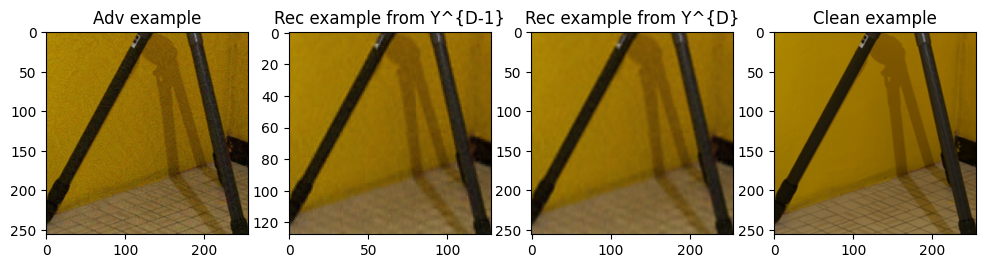

In [7]:
x_rec_output = x_rec.squeeze().cpu().detach().numpy().transpose(1, 2, 0)
x_rec_output.shape

(256, 256, 3)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


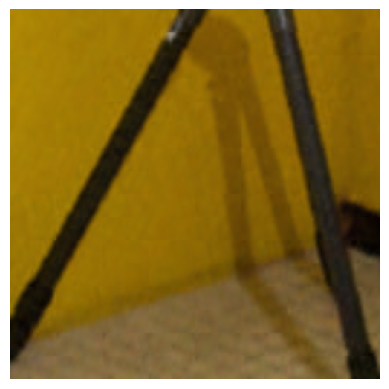

In [10]:
import matplotlib.pyplot as plt

x_rec_show = x_rec.squeeze().cpu().detach().numpy().transpose(1, 2, 0)


# 绘制误差图
plt.imshow(x_rec_show)
# plt.title("Error Map (RGB Mean MAE)")
# plt.colorbar()
plt.axis("off")

plt.savefig('./tt0.png',
            bbox_inches='tight',
            dpi=300,
            pad_inches=0)

plt.show()